<a href="https://colab.research.google.com/github/Andreana-yusuf/Heart-Disease-Dataset/blob/main/heart_disease_classifications.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [11]:
import os
import pandas as pd


# Baca dataset
df = pd.read_csv('heart.csv')

print(f"Ukuran dataset: {df.shape[0]} baris, {df.shape[1]} kolom")
print("\nJumlah missing values per kolom:")
print(df.isnull().sum())
print("\nDistribusi target (0 = Sehat, 1 = Penyakit Jantung):")
print(df['target'].value_counts())

df.head()

Ukuran dataset: 1025 baris, 14 kolom

Jumlah missing values per kolom:
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
target      0
dtype: int64

Distribusi target (0 = Sehat, 1 = Penyakit Jantung):
target
1    526
0    499
Name: count, dtype: int64


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,52,1,0,125,212,0,1,168,0,1.0,2,2,3,0
1,53,1,0,140,203,1,0,155,1,3.1,0,0,3,0
2,70,1,0,145,174,0,1,125,1,2.6,0,0,3,0
3,61,1,0,148,203,0,1,161,0,0.0,2,1,3,0
4,62,0,0,138,294,1,1,106,0,1.9,1,3,2,0


Ukuran dataset: 1025 baris, 14 kolom
Jumlah baris duplikat: 723

==================== Logistic Regression ====================
              precision    recall  f1-score   support

           0       0.89      0.70      0.78       100
           1       0.76      0.91      0.83       105

    accuracy                           0.81       205
   macro avg       0.82      0.81      0.81       205
weighted avg       0.82      0.81      0.81       205


==================== K-Nearest Neighbors (k=5) ====================
              precision    recall  f1-score   support

           0       0.85      0.87      0.86       100
           1       0.87      0.86      0.87       105

    accuracy                           0.86       205
   macro avg       0.86      0.86      0.86       205
weighted avg       0.86      0.86      0.86       205


==================== Support Vector Machine (RBF) ====================
              precision    recall  f1-score   support

           0       0.94

,Model,CV ROC-AUC (Mean),Test Accuracy,Test F1-Score,Test ROC-AUC
4,Random Forest,0.9984,1.0000,1.0000,1.0000
2,Support Vector Machine (RBF),0.9706,0.9268,0.9296,0.9771
1,K-Nearest Neighbors (k=5),0.9486,0.8634,0.8654,0.9629
3,Decision Tree,0.9450,0.8732,0.8785,0.9326
0,Logistic Regression,0.9157,0.8098,0.8312,0.9298


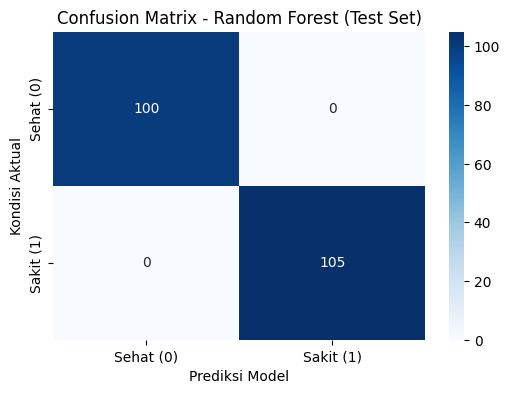

In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

# 5 Model Klasik (Pertemuan 2 - 7)
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

# Metrik Evaluasi
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, accuracy_score, f1_score

# 1. Load & Cek Data Asli (1.025 baris)
df = pd.read_csv('heart.csv')
print(f"Ukuran dataset: {df.shape[0]} baris, {df.shape[1]} kolom")

# Cek duplikat (catatan penting untuk bagian keterbatasan/analisis di laporan)
print(f"Jumlah baris duplikat: {df.duplicated().sum()}")

# 2. Pisahkan Fitur (X) dan Target (y)
X = df.drop('target', axis=1)
y = df['target']

# Split Train & Test (80% Latih, 20% Uji) dengan Stratifikasi
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 3. Definisi 5 Model Klasik
models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
    'K-Nearest Neighbors (k=5)': KNeighborsClassifier(n_neighbors=5),
    'Support Vector Machine (RBF)': SVC(probability=True, random_state=42),
    'Decision Tree': DecisionTreeClassifier(max_depth=5, random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=42)
}

# 4. Pelatihan & Evaluasi (Stratified 5-Fold CV + Test Set)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
results = []

for name, model in models.items():
    # Pipeline mencegah data leakage saat scaling
    pipe = Pipeline([
        ('scaler', StandardScaler()),
        ('classifier', model)
    ])

    # Cross-validation pada data latih
    cv_scores = cross_val_score(pipe, X_train, y_train, cv=cv, scoring='roc_auc')

    # Latih penuh & uji pada test set
    pipe.fit(X_train, y_train)
    y_pred = pipe.predict(X_test)
    y_proba = pipe.predict_proba(X_test)[:, 1]

    results.append({
        'Model': name,
        'CV ROC-AUC (Mean)': round(cv_scores.mean(), 4),
        'Test Accuracy': round(accuracy_score(y_test, y_pred), 4),
        'Test F1-Score': round(f1_score(y_test, y_pred), 4),
        'Test ROC-AUC': round(roc_auc_score(y_test, y_proba), 4)
    })

    print(f"\n==================== {name} ====================")
    print(classification_report(y_test, y_pred))

# 5. Tabel Perbandingan Semua Model
print("\n=== RINGKASAN PERBANDINGAN MODEL ===")
results_df = pd.DataFrame(results).sort_values(by='Test ROC-AUC', ascending=False)
display(results_df)

# 6. Visualisasi Confusion Matrix Model Terbaik (Random Forest)
best_pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('classifier', RandomForestClassifier(n_estimators=100, random_state=42))
])
best_pipe.fit(X_train, y_train)
y_pred_best = best_pipe.predict(X_test)

plt.figure(figsize=(6, 4))
sns.heatmap(confusion_matrix(y_test, y_pred_best), annot=True, fmt='d', cmap='Blues',
            xticklabels=['Sehat (0)', 'Sakit (1)'], yticklabels=['Sehat (0)', 'Sakit (1)'])
plt.title('Confusion Matrix - Random Forest (Test Set)')
plt.xlabel('Prediksi Model')
plt.ylabel('Kondisi Aktual')
plt.show()